# Project 2: Portfolio Optimization, PCA, and Dynamic Allocation

Implement generalized deviation-risk optimization, mean--variance and PCA factor models, validation/test portfolio selection, and a multi-period portfolio optimization extension.

Use the supplied `Project2_returns.csv`. May use NumPy, pandas, Matplotlib, and CVXPY, with a suitable convex solver.


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cvxpy as cp
import time
from pathlib import Path

ANNUALIZATION = 252

## Data

Use these 16 assets in the given order:

`GOOG, TSLA, AAPL, GS, A, AAP, MSFT, AMZN, NVDA, JPM, XOM, JNJ, PG, WMT, CAT, BA`.

- **Training:** 2017-01-01 to 2018-12-31
- **Validation:** 2019-01-01 to 2019-06-30
- **Test:** 2019-07-01 to 2019-12-31

For asset $j$ on day $s$, define the open-to-close return

$$
r_{j,s}=\frac{p^c_{j,s}-p^o_{j,s}}{p^o_{j,s}}.
$$

For any estimation sample, let $\bar r$ and $\widehat\Sigma$ denote the sample mean and covariance of the **daily** returns (use denominator $N-1$). Use the annualized inputs

$$
\mu=252\bar r,\qquad Q=252\widehat\Sigma.
$$

All candidate models in Tasks 1--2 must be fitted using training data only. Task 3 uses the original daily returns for P&L. Task 4 uses separate quarterly estimates within the training period.

Portfolio weights satisfy $x\ge0$ and $\mathbf1^\top x=1$.


In [9]:
# as given in project 2 instruction notebook
asset_lst = [
    'GOOG', 'TSLA', 'AAPL', 'GS',
    'A', 'AAP', 'MSFT', 'AMZN',
    'NVDA', 'JPM', 'XOM', 'JNJ',
    'PG', 'WMT', 'CAT', 'BA'
]

data_path = Path('/content/sample_data/Project2_returns.csv')

if data_path.exists():
    # Preferred: the supplied fixed sample of daily open-to-close returns.
    returns = pd.read_csv(data_path, parse_dates=['Date'], index_col='Date')
    missing_assets = sorted(set(asset_lst) - set(returns.columns))
    if missing_assets:
        raise ValueError(f'Missing assets in the supplied data: {missing_assets}')
    returns = returns.reindex(columns=asset_lst)
    data_source = str(data_path)
else:
    import yfinance as yfin

    # yfinance treats the end date as exclusive.
    data = yfin.download(
        asset_lst,
        start='2017-01-01',
        end='2020-01-01',
        auto_adjust=True,
        progress=False
    )
    if data.empty:
        raise RuntimeError(
            'The download returned no data. Place the supplied '
            'Project2_returns.csv beside this notebook and rerun.'
        )

    open_prices = data['Open'].reindex(columns=asset_lst).dropna(how='any')
    close_prices = data['Close'].reindex(columns=asset_lst).dropna(how='any')
    common_dates = open_prices.index.intersection(close_prices.index)
    open_prices = open_prices.loc[common_dates]
    close_prices = close_prices.loc[common_dates]
    returns = close_prices / open_prices - 1
    data_source = 'yfinance download'

returns = returns.sort_index().loc['2017-01-01':'2019-12-31']
returns = returns.replace([np.inf, -np.inf], np.nan).dropna(how='any')
assert returns.columns.tolist() == asset_lst
assert returns.index.is_unique
assert not returns.empty
assert np.isfinite(returns.to_numpy()).all()

train_returns = returns.loc[
    (returns.index >= '2017-01-01') & (returns.index < '2019-01-01')
].copy()
validation_returns = returns.loc[
    (returns.index >= '2019-01-01') & (returns.index < '2019-07-01')
].copy()
test_returns = returns.loc[
    (returns.index >= '2019-07-01') & (returns.index < '2020-01-01')
].copy()

if any(frame.empty for frame in (train_returns, validation_returns, test_returns)):
    raise ValueError('At least one required data period is empty.')

print('Data source:', data_source)
print('Training shape:', train_returns.shape)
print('Validation shape:', validation_returns.shape)
print('Test shape:', test_returns.shape)


Data source: /content/sample_data/Project2_returns.csv
Training shape: (502, 16)
Validation shape: (124, 16)
Test shape: (128, 16)


## Task 1: Generalized deviation-risk portfolio optimization

For $p\ge1$, define

$$
\rho_p(x)=\left[\frac1N\sum_{s=1}^{N}
|(r_s-\bar r)^\top x|^p\right]^{1/p},
\qquad
\widetilde\rho_p(x)=\sqrt{252}\,\rho_p(x),
$$

where $N$ is the number of training observations and $\bar r$ is the daily training mean. The latter is a scaled daily-deviation measure.

Solve

$$
\min_x\quad -\mu^\top x+\lambda\widetilde\rho_p(x)
\quad\text{s.t.}\quad x\ge0,\ \mathbf1^\top x=1.
$$

Use $p\in\{2,3,4,6\}$ and at least **25 values of $\lambda$ for each $p$**, chosen using training data.

### Requirements

1. Implement the optimization and store the weights and parameters for each candidate.
2. Plot the training return--deviation-risk tradeoff for representative values of $p$.
3. Compare the resulting portfolios and discuss the effect of $p$. Also report their annualized volatility under the training covariance $Q$.


### Selected Optimization Solvers: CLARABEL, ECOS, and SCS

For this problem, I use CVXPY to formulate and solve the generalized deviation-risk portfolio optimization:

$$
\min_x -\mu^\top x+\lambda\widetilde{\rho}_p(x)
$$

subject to $x \geq 0$ and $\mathbf{1}^\top x = 1$.

CVXPY sets up the optimization problem, while CLARABEL, ECOS, and SCS are different solvers that calculate the optimal portfolio weights.

- **CLARABEL:** Uses an interior-point method and generally provides accurate solutions for convex optimization problems. I use this as my first choice because the problem has only 16 assets and is relatively small.
- **ECOS:** Also uses an interior-point method and works well for many convex optimization problems. I use it as a backup if CLARABEL fails or is unavailable.
- **SCS:** Uses a first-order splitting method, which can be useful for larger optimization problems but may be less accurate. I use it as a final backup.

In my code, I try these solvers in order: CLARABEL, ECOS, then SCS. If one solver successfully finds an optimal solution, the code moves on to the next combination of $p$ and $\lambda$.

All three solvers attempt to solve the same optimization problem, so their results should be similar, although small numerical differences may occur.

Using multiple solvers makes the optimization more reliable across the different values of $p \in \{2,3,4,6\}$ and $\lambda$. For each successful optimization, I store the resulting portfolio weights, expected annualized return, deviation risk, and annualized volatility for comparison.


### Part 1

In [10]:
R = train_returns.to_numpy(dtype=float)
# converts the training returns into a numpy array of floats
N, n_assets = R.shape
# gets the number of observations and assets
r_bar = R.mean(axis=0)
# calculates the average daily return for each asset
D = R - r_bar
# centered daily asset returns
# subtracts each asset's mean return to get its daily deviations
mu = ANNUALIZATION * r_bar
# annualized expected returns
# converts average daily returns into annualized expected returns
Q = ANNUALIZATION * np.cov(R, rowvar=False, ddof=1)
# calculates the annualized sample covariance matrix
P_VALUES = (2, 3, 4, 6)
# defines the four p values used in the optimization

if not (np.isfinite(D).all() and np.isfinite(mu).all() and np.isfinite(Q).all()):
    # checks whether all return, deviation, and covariance values are finite
    raise ValueError('Nonfinite training inputs')
    # raises an error if any training inputs are invalid

candidate_rows = []
# creates an empty list to store the results of each portfolio
for p in P_VALUES:
    # repeats the optimization for each p value
    # select lambda using training data only. Make the scale comparable
    # to the annualized mean-return spread for this particular p.
    single_asset_risk = np.sqrt(ANNUALIZATION) * np.mean(
        # calculates the annualized deviation risk for each individual asset
        np.abs(D) ** p, axis=0
        # raises each absolute deviation to the power of p and averages by asset
    ) ** (1 / p)
    # takes the pth root to finish calculating the deviation risk
    lambda_ref = np.ptp(mu) / np.median(single_asset_risk)
    # sets a reference lambda based on the return spread relative to median risk
    lambda_grid = np.unique(np.r_[0.0, 1.0,
        # starts a grid of lambda values including zero and one
        # tiny lambdas all give the same 100% TSLA portfolio and huge lambdas all give the
        # same minimum-risk portfolio. The narrower range (0.03 to 30) covers the part of the
        # frontier where the portfolio actually changes, so every candidate is distinct.
        # lambda = 0 (max-return portfolio) is still included separately above.
        lambda_ref*np.geomspace(0.03, 30, 40)])
        # adds 40 logarithmically spaced values scaled by the reference lambda
    assert len(lambda_grid) >= 25
    # makes sure at least 25 distinct lambda values are tested

    w = cp.Variable(n_assets, nonneg=True)
    # creates nonnegative portfolio weight variables to prevent short selling
    lam = cp.Parameter(nonneg=True)
    # creates a nonnegative parameter for the risk penalty lambda
    centered_portfolio_returns = D @ w
    # calculates the portfolio's centered daily returns using its weights
    deviation_risk = (np.sqrt(ANNUALIZATION) / N ** (1 / p)) * cp.pnorm(
        # sets up the annualized p-norm deviation risk measure
        centered_portfolio_returns, p=p)
        # applies the p-norm to the centered portfolio returns
    # completes the deviation risk expression
    problem = cp.Problem(cp.Minimize(-mu @ w + lam * deviation_risk), [cp.sum(w) == 1])
    # minimizes negative expected return plus the weighted risk penalty
    # requires all portfolio weights to sum to one

    t0 = time.perf_counter()
    # records the starting time for this p value
    for lambda_value in lambda_grid:
        # solves the optimization for each lambda value
        lam.value = float(lambda_value)
        # updates the risk penalty without rebuilding the optimization problem
        solved = False
        # initializes a flag to track whether the optimization succeeds
        for solver in ('CLARABEL', 'ECOS', 'SCS'):
            # tries clarabel, ecos, and scs in that order
            if solver not in cp.installed_solvers():
                # checks whether the selected solver is installed
                continue
                # skips the solver if it is unavailable
            try:
                # attempts to solve the optimization using the current solver
                kwargs = {'eps': 1e-6, 'max_iters': 20000} if solver == 'SCS' else {}
                # sets the tolerance and iteration limit for scs only
                problem.solve(solver=solver, warm_start=True, **kwargs)
                # solves the problem using the selected solver and previous solution
                if problem.status in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
                    # checks whether the solver found an acceptable solution
                    solved = True
                    # marks the optimization as successfully solved
                    break
                    # stops trying other solvers once a solution is found
            except cp.error.SolverError:
                # catches errors if the current solver fails
                pass
                # moves on without stopping the entire optimization
        if not solved or w.value is None:
            # checks whether all solvers failed or no weights were returned
            raise RuntimeError(f'Solver failed for p={p}, lambda={lambda_value:.6g}')
            # raises an error identifying the p and lambda values that failed

        weights = np.maximum(np.asarray(w.value).ravel(), 0.0)
        # converts the optimized weights into an array and removes negative numerical errors
        weights /= weights.sum()  # removes only numerical constraint residuals
        # normalizes the weights so that they sum to exactly one
        centered_r = D @ weights
        # calculates the centered returns of the optimized portfolio
        row = {
            # creates a dictionary to store the current portfolio's results
            'p': p,
            # records the p value used for the risk measure
            'lambda': float(lambda_value),
            # records the lambda value used for the risk penalty
            'train_return': float(mu @ weights),
            # calculates the portfolio's annualized expected training return
            'deviation_risk': float(np.sqrt(ANNUALIZATION) *
            # starts calculating the annualized p-deviation risk of the portfolio
                                   np.mean(np.abs(centered_r) ** p) ** (1 / p)),
            # calculates the pth root of the mean absolute deviations raised to p
            'annual_volatility': float(np.sqrt(max(weights @ Q @ weights, 0.0))),
            # calculates annualized volatility from the portfolio covariance
            'solver': solver,
            # records which solver successfully solved the problem
            'solver_status': problem.status,
            # records the solver's reported optimization status
        }
        # completes the dictionary of portfolio results
        row.update({f'w_{asset}': float(weights[i])
        # adds each asset's optimized portfolio weight to the results dictionary
                    for i, asset in enumerate(asset_lst)})
                    # matches each asset name with its corresponding weight
        candidate_rows.append(row)
        # stores the current portfolio as another candidate
    print(f'p={p}: {len(lambda_grid)} candidates; '
    # displays the p value and number of candidate portfolios tested
          f'{time.perf_counter() - t0:.1f} sec')
          # displays the total computation time for this p value

candidates = pd.DataFrame(candidate_rows).sort_values(
# converts all candidate portfolios into a dataframe and begins sorting
    ['p', 'lambda']).reset_index(drop=True)
    # sorts by p and lambda and resets the dataframe index
print('Total candidate portfolios:', len(candidates))
# displays the total number of portfolios generated
assert all(candidates.groupby('p').size() >= 25)
# verifies that at least 25 portfolios were generated for each p value
assert np.allclose(candidates[[f'w_{a}' for a in asset_lst]].sum(axis=1), 1,
# checks that every portfolio's asset weights sum to approximately one
                   atol=1e-5)
                   # allows a small numerical tolerance when checking the weights

# confirms the lambda grid is not wasting candidates
# counts portfolios per p with distinct weights (rounded to 3 decimals)
for p_check, group in candidates.groupby('p'):
    n_distinct = len(group[[f'w_{a}' for a in asset_lst]].round(3).drop_duplicates())
    print(f'p={p_check}: {n_distinct} distinct portfolios out of {len(group)} candidates')

display(candidates[['p', 'lambda', 'train_return', 'deviation_risk', 'annual_volatility']])
# displays the p values, lambda values, and expected training returns
# includes the deviation risk and annualized volatility for comparison

p=2: 42 candidates; 1.1 sec
p=3: 42 candidates; 4.2 sec
p=4: 42 candidates; 4.4 sec
p=6: 42 candidates; 7.2 sec
Total candidate portfolios: 168
p=2: 37 distinct portfolios out of 42 candidates
p=3: 36 distinct portfolios out of 42 candidates
p=4: 36 distinct portfolios out of 42 candidates
p=6: 36 distinct portfolios out of 42 candidates


,p,lambda,train_return,deviation_risk,annual_volatility
0,2,0.000000,0.179786,0.397937,0.398334
1,2,0.076437,0.179786,0.397937,0.398334
2,2,0.091248,0.179786,0.397937,0.398334
3,2,0.108930,0.179786,0.397937,0.398334
4,2,0.130038,0.179786,0.397937,0.398334
...,...,...,...,...,...
163,6,17.097988,0.025759,0.234827,0.105907
164,6,20.411178,0.019356,0.234483,0.106006
165,6,24.366388,0.014380,0.234258,0.106138
166,6,29.088024,0.011518,0.234150,0.106106


In [11]:
print(candidates.groupby(['p', 'solver_status']).size().rename('count'))
# displays the number of candidate portfolios for each p value and solver status

inaccurate = candidates.loc[candidates['solver_status'] != cp.OPTIMAL]
# selects portfolios whose solver status is not fully optimal

if not inaccurate.empty:
    # checks whether any portfolios have potentially inaccurate solutions
    print('Warning: Review the following portfolio solutions:')
    # displays a warning if any portfolios require additional review
    display(inaccurate[['p', 'lambda', 'solver', 'solver_status']])
    # displays the p values, lambda values, solvers, and statuses requiring review

candidate_path = 'task1_candidates.csv'
# defines the filename used to save all candidate portfolios
candidates.to_csv(candidate_path, index=False)
# exports the candidate portfolio results to a csv file without the dataframe index
print('Saved', candidate_path, 'with', len(candidates), 'candidate portfolios')
# confirms the saved filename and total number of candidate portfolios

p  solver_status
2  optimal          42
3  optimal          42
4  optimal          42
6  optimal          42
Name: count, dtype: int64
Saved task1_candidates.csv with 168 candidate portfolios


## Visualization of the Data (Above)




### Part 2

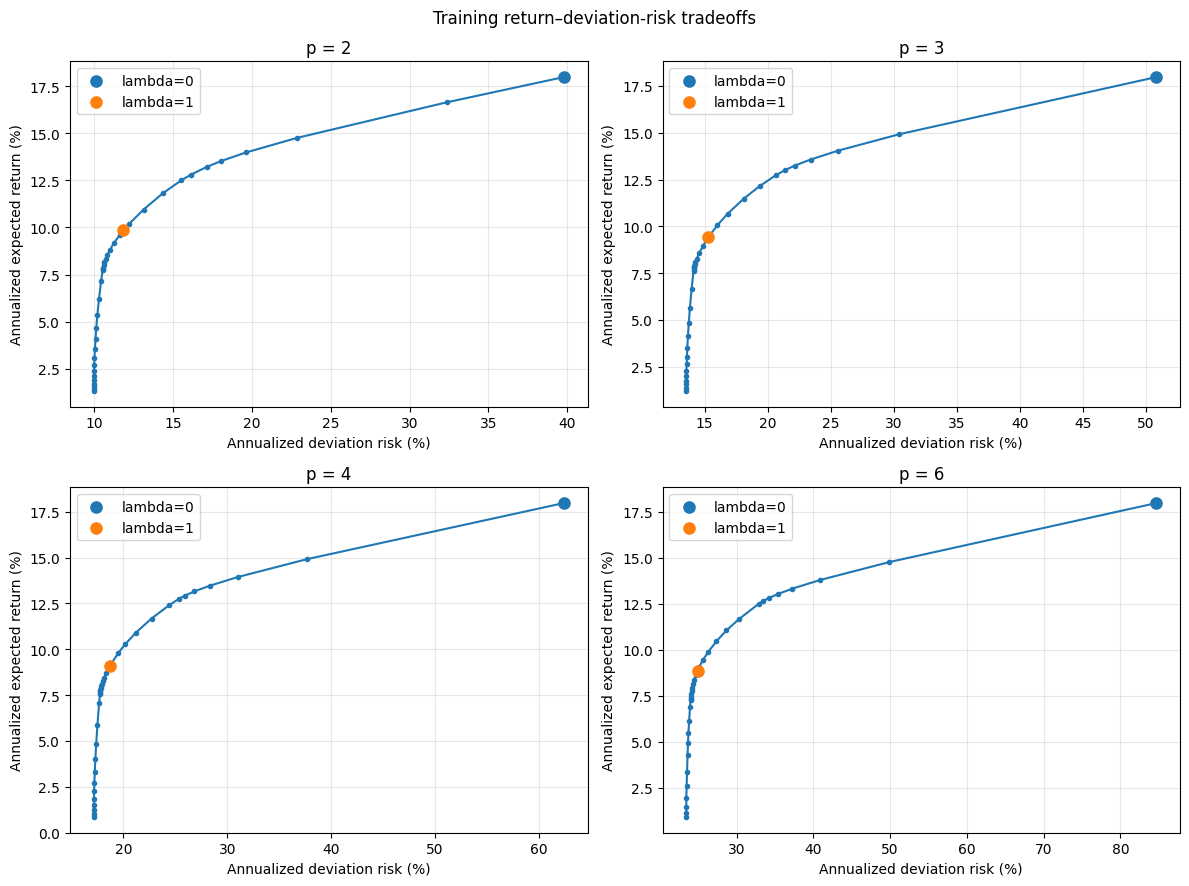

In [12]:

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
# creates a figure with four subplots arranged in a 2x2 grid

for ax, p in zip(axes.flat, P_VALUES):
    # loops through each subplot and assigns one value of p to it

    curve = candidates.loc[candidates['p'] == p].sort_values('deviation_risk')
    # selects all portfolios for the current p and sorts them by deviation risk

    ax.plot(100 * curve['deviation_risk'], 100 * curve['train_return'], 'o-', linewidth=1.5, markersize=3)
    # plots annualized deviation risk against expected return as percentages
    # connects the portfolio results to show the risk-return tradeoff

    for label, value in [('lambda=0', 0.0), ('lambda=1', 1.0)]:
        # loops through two specific lambda values to highlight them

        point = candidates.loc[(candidates['p'] == p) & np.isclose(candidates['lambda'], value)].iloc[0]
        # finds the portfolio corresponding to the current p and lambda value

        ax.scatter(100 * point['deviation_risk'], 100 * point['train_return'], s=65, zorder=3, label=label)
        # highlights the selected portfolio with a larger marker
        # zorder makes sure the marker appears above the plotted curve

    ax.set_title(f'p = {p}')
    # labels the subplot with its corresponding p value

    ax.set_xlabel('Annualized deviation risk (%)')
    # labels the horizontal axis as annualized deviation risk

    ax.set_ylabel('Annualized expected return (%)')
    # labels the vertical axis as annualized expected return

    ax.grid(alpha=0.3)
    # adds a light grid to make the graph easier to read

    ax.legend()
    # displays the legend identifying the two highlighted lambda values

plt.suptitle('Training return–deviation-risk tradeoffs')
# adds an overall title above all four subplots

plt.tight_layout()
# adjusts the spacing so the subplots and labels do not overlap

plt.show()
# displays the completed figure


### Part 2: Interpretation

The four graphs show the relationship between annualized expected return and deviation risk for $p=2,3,4,6$. Each point represents an optimized portfolio at a different $\lambda$, which controls the penalty on risk.

Across all four graphs, increasing $\lambda$ reduces both expected return and deviation risk. At $\lambda=0$, all models select the 100% TSLA portfolio, which has the highest training mean return (approximately 18%). At $\lambda=1$, expected returns decrease to approximately 9–10%, with substantially lower deviation risks.

All four curves show that risk reduction becomes increasingly costly in terms of expected return. Near the minimum-risk end, the curves become almost vertical: further increases in $\lambda$ produce small reductions in risk but larger declines in return. This is consistent with the frontier's slope equaling $\lambda$ wherever differentiable.

The $\lambda$ grids were selected using training data to capture meaningful changes in portfolio allocations. Small $\lambda$ values favor maximum return, while large values approach the minimum-risk portfolio.

Although the curves have similar shapes, their deviation-risk values are not directly comparable across different $p$. Higher $p$ values place greater weight on extreme deviations, changing which portfolios the optimization prefers.

Overall, $\lambda$ determines the risk-return tradeoff, while $p$ determines how deviations are penalized and influences the resulting portfolio allocations.

### Part 3

,Annualized return,p-deviation risk,Covariance volatility,Nonzero assets (> 0.1%),Largest holdings
p,,,,,
2,9.85%,11.85%,11.86%,6,"WMT 45.0%, PG 18.5%, JNJ 15.9%"
3,9.41%,15.29%,11.53%,6,"WMT 45.3%, PG 24.9%, JNJ 16.7%"
4,9.06%,18.68%,11.42%,5,"WMT 46.4%, PG 28.5%, JNJ 17.9%"
6,8.87%,24.90%,11.62%,3,"WMT 49.1%, PG 33.8%, JNJ 17.1%"


,GOOG,TSLA,AAPL,GS,A,AAP,MSFT,AMZN,NVDA,JPM,XOM,JNJ,PG,WMT,CAT,BA
p,,,,,,,,,,,,,,,,
2,0.00%,7.30%,6.24%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,15.87%,18.52%,44.95%,0.00%,7.12%
3,0.00%,4.86%,5.65%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,16.72%,24.92%,45.35%,0.00%,2.50%
4,0.00%,2.24%,4.92%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,17.88%,28.55%,46.41%,0.00%,0.00%
6,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,17.10%,33.85%,49.06%,0.00%,0.00%


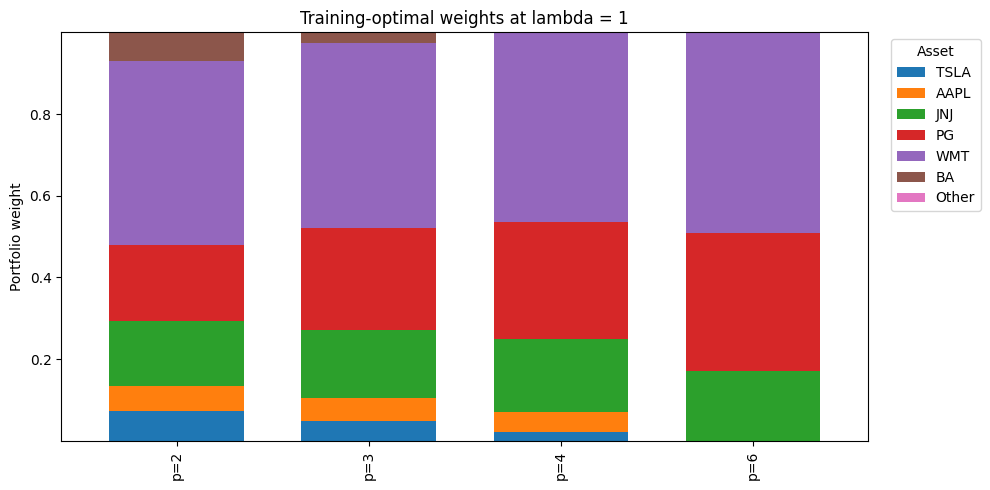

In [13]:

benchmark = candidates.loc[np.isclose(candidates['lambda'], 1.0)].copy()
# selects all candidate portfolios with lambda approximately equal to 1 and creates a copy
benchmark = benchmark.set_index('p').loc[list(P_VALUES)]
# sets p as the index and arranges the portfolios in the specified order of p values
weights_at_one = benchmark[[f'w_{a}' for a in asset_lst]].copy()
# extracts the portfolio weights for each asset at lambda equal to 1
weights_at_one.columns = asset_lst
# renames the weight columns to their corresponding asset tickers
summary_rows = []
# initializes an empty list to store the portfolio comparison results

for p, row in benchmark.iterrows():
    # loops through each p value and its corresponding portfolio data
    ws = weights_at_one.loc[p].sort_values(ascending=False)
    # retrieves the portfolio weights for the current p and sorts them from largest to smallest
    top_three = ', '.join(f'{asset} {weight:.1%}' for asset, weight in ws.head(3).items())
    # identifies the three largest holdings and formats their weights as percentages
    summary_rows.append({
        # adds a dictionary containing the current portfolio's summary statistics
        'p': p,
        # stores the current p value
        'Annualized return': row['train_return'],
        # stores the expected annualized return calculated from the training data
        'p-deviation risk': row['deviation_risk'],
        # stores the annualized deviation risk corresponding to the current p value
        'Covariance volatility': row['annual_volatility'],
        # stores the annualized volatility calculated using the training covariance matrix
        'Nonzero assets (> 0.1%)': int((ws > 1e-3).sum()),
        # counts the number of assets with portfolio weights greater than 0.1 percent
        'Largest holdings': top_three,
        # stores the three assets with the highest portfolio weights
    })
    # completes the dictionary and adds it to the summary list

summary = pd.DataFrame(summary_rows).set_index('p')
# converts the summary list into a dataframe and uses p as the index
display(summary.style.format({
    # displays the summary table with percentage formatting for the selected columns
    'Annualized return': '{:.2%}',
    # formats the annualized expected return as a percentage with two decimal places
    'p-deviation risk': '{:.2%}',
    # formats the annualized deviation risk as a percentage with two decimal places
    'Covariance volatility': '{:.2%}',
    # formats the annualized covariance volatility as a percentage with two decimal places
}))
# completes the formatting instructions and displays the summary table

display(weights_at_one.style.format('{:.2%}'))
# displays the portfolio weights for all 16 assets as percentages with two decimal places

major_assets = weights_at_one.columns[(weights_at_one.max(axis=0) >= 0.01)]
# identifies assets that have at least a 1 percent weight in any of the four portfolios

plot_weights = weights_at_one[major_assets].copy()
# creates a dataframe containing only the selected major assets

plot_weights['Other'] = weights_at_one.drop(columns=major_assets).sum(axis=1)
# combines the weights of all remaining smaller holdings into an other category

plot_weights.index = [f'p={p}' for p in plot_weights.index]
# renames the index labels to show the corresponding p values

ax = plot_weights.plot.bar(stacked=True, figsize=(10, 5), width=0.7)
# creates a stacked bar chart showing the portfolio allocation for each p value

ax.set_title('Training-optimal weights at lambda = 1')
# sets the chart title to describe the optimized portfolios being compared

ax.set_ylabel('Portfolio weight')
# labels the vertical axis as portfolio weight

ax.set_xlabel('')
# removes the horizontal axis label since the p values are already shown

ax.legend(title='Asset', bbox_to_anchor=(1.02, 1), loc='upper left')
# adds a legend identifying each asset and positions it outside the chart on the right

plt.tight_layout()
# adjusts the chart spacing to prevent the labels and legend from overlapping

plt.show()
# displays the completed stacked bar chart


In [14]:
# compare the four p values at the SAME expected return instead of the same lambda.
# at a fixed lambda = 1 the penalty has a different effective strength for each p (the deviation-risk
# scales differ), so differences in return/volatility mix the effect of p with the effect of penalty size
# here, for each p, we minimize the p-deviation risk subject to a common minimum annualized return
target_return = 0.09
# common annualized return target (9%), feasible for all p because the lambda=0 portfolios earn about 18%
matched_rows = []
# creates an empty list to store the matched-return results
for p in P_VALUES:
    # repeats the optimization for each p value
    w_m = cp.Variable(n_assets, nonneg=True)
    # nonnegative portfolio weights (no short selling)
    dev_m = (np.sqrt(ANNUALIZATION) / N ** (1 / p)) * cp.pnorm(D @ w_m, p=p)
    # annualized p-norm deviation risk, same definition as in Part 1
    prob_m = cp.Problem(cp.Minimize(dev_m), [cp.sum(w_m) == 1, mu @ w_m >= target_return])
    # minimizes deviation risk subject to full investment and the minimum return target
    prob_m.solve(solver='CLARABEL')
    # solves the problem with CLARABEL
    assert prob_m.status == cp.OPTIMAL
    # makes sure the solver found an optimal solution
    x_m = np.maximum(np.asarray(w_m.value).ravel(), 0.0)
    # removes tiny negative numerical errors
    x_m /= x_m.sum()
    # renormalizes the weights so they sum to exactly one
    ws_m = pd.Series(x_m, index=asset_lst).sort_values(ascending=False)
    # sorts the weights from largest to smallest
    matched_rows.append({
        'p': p,
        'Annualized return': float(mu @ x_m),
        'p-deviation risk': float(np.sqrt(ANNUALIZATION) *
                                  np.mean(np.abs(D @ x_m) ** p) ** (1 / p)),
        'Covariance volatility': float(np.sqrt(x_m @ Q @ x_m)),
        'Nonzero assets (> 0.1%)': int((ws_m > 1e-3).sum()),
        'Largest holdings': ', '.join(f'{a} {v:.1%}' for a, v in ws_m.head(3).items()),
    })
    # stores return, deviation risk, covariance volatility, number of holdings and top three holdings

matched = pd.DataFrame(matched_rows).set_index('p')
# converts the results into a dataframe indexed by p
display(matched.style.format({
    'Annualized return': '{:.2%}',
    'p-deviation risk': '{:.2%}',
    'Covariance volatility': '{:.2%}',
}))
# display the matched-return comparison table

,Annualized return,p-deviation risk,Covariance volatility,Nonzero assets (> 0.1%),Largest holdings
p,,,,,
2,9.00%,11.12%,11.13%,7,"WMT 36.3%, PG 26.4%, JNJ 17.2%"
3,9.00%,14.91%,11.21%,6,"WMT 41.4%, PG 28.3%, JNJ 17.1%"
4,9.00%,18.62%,11.37%,5,"WMT 45.8%, PG 29.0%, JNJ 17.9%"
6,9.00%,25.04%,11.73%,3,"WMT 51.4%, PG 30.8%, JNJ 17.8%"


### Part 3: Portfolio Comparison and Discussion

I compared the optimized portfolios for $p=2,3,4,6$ at $\lambda=1$, examining their annualized expected returns, deviation risks, covariance volatilities, and asset allocations. Since deviation-risk scales differ across $p$, I also compared portfolios at a common 9% annualized expected return to isolate the effect of $p$.

#### Summary of Results

At $\lambda=1$, increasing $p$ from 2 to 6 decreases annualized expected return from 9.85% to 8.87%, while reported deviation risk increases from 11.85% to 24.90%. However, deviation-risk values are not directly comparable across $p$ because higher values place greater weight on extreme deviations.

Annualized covariance volatility decreases from 11.86% ($p=2$) to 11.42% ($p=4$), before increasing to 11.62% ($p=6$). This non-monotonic pattern partly reflects differences in expected return, since the portfolios are not being compared at a fixed return.

#### Portfolio Allocation and Interpretation

At $p=2$, the portfolio contains six assets with weights above 0.1%, primarily WMT (44.95%), PG (18.52%), and JNJ (15.87%), with smaller allocations to TSLA, AAPL, and BA.

As $p$ increases, weights shift toward WMT and PG, while TSLA, AAPL, and BA receive smaller allocations. At $p=6$, only three assets remain above 0.1%: WMT (49.06%), PG (33.85%), and JNJ (17.10%).

Thus, higher $p$ values produce more concentrated portfolios, suggesting that WMT, PG, and JNJ were relatively effective at limiting larger deviations in the training sample.

#### Matched-Return Comparison (9% Annualized Return)

At a common 9% expected return, the number of holdings above 0.1% decreases from 7 to 6 to 5 to 3 as $p$ increases. WMT's allocation also increases from 36.3% to 51.4%, confirming that higher $p$ values favor greater concentration even when expected return is held constant.

Covariance volatility increases monotonically from 11.13% ($p=2$) to 11.21% ($p=3$), 11.37% ($p=4$), and 11.73% ($p=6$).

The $p=2$ portfolio has the lowest volatility because its deviation-risk measure is proportional to covariance standard deviation. With $N=502$ training observations,

$$
\widetilde{\rho}_2(x)=\sqrt{\frac{501}{502}}\sqrt{x^\top Qx}
$$

Therefore, minimizing $p=2$ deviation risk at a fixed return is equivalent to minimizing covariance volatility. Higher $p$ values prioritize larger deviations instead, potentially producing higher standard deviation.

#### Overall Takeaways

Increasing $p$ produces more concentrated portfolios, particularly in WMT, PG, and JNJ. At $\lambda=1$, expected returns decrease, but the effective risk penalties also differ across $p$.

At a common 9% expected return, covariance volatility increases with $p$, confirming that minimizing higher-order deviation risk does not necessarily minimize standard deviation.

These findings are specific to the 2017–2018 training sample. Validation and test results are needed to assess out-of-sample performance, and deviation-risk values should not be directly compared across different $p$ values.